# Assignment 15 --- Clean vs. dirty places with CNN, Transformer and Mamba backbones

**Md. Shoaib Abdullah Khan · ID: 2010976135**

Six ImageNet-pretrained backbones of similar size (22--35 M parameters), two from each family, are fine-tuned to
classify mobile-phone photographs as **Clean** or **Dirty**:

| family | models |
|---|---|
| CNN | ResNet-50, ConvNeXt-Tiny |
| Transformer | ViT-Small/16, Swin-Tiny |
| Mamba | MambaVision-T, MambaVision-T2 |

| Task | Where |
|---|---|
| 1. Dataset collection | §1 |
| 2. Labelling and train / validation / test split | §1 |
| 3. Pretrained backbones and fine-tuning | §3, §4 |
| 4. Accuracy, precision, recall, F1, confusion matrices | §4, §5 |
| 5. Performance, computational requirements, inference speed | §5, §6, §7 |
| 6. Correctly / incorrectly classified images and factors affecting performance | §8, §9, §10 |

**Dirty = positive class** for precision, recall and F1.

## 0. Environment

MambaVision (NVIDIA, CVPR 2025) is loaded from the Hugging Face hub. Its Mamba mixer needs `selective_scan_fn` from the
`mamba-ssm` package, which only exists as a compiled CUDA kernel and cannot be built on this Windows machine (no CUDA
toolkit). `third_party/mamba_ssm` provides the same function in pure PyTorch, following the official reference
implementation (`selective_scan_ref`). It computes a chunked closed-form scan; §3 checks that it matches the step-by-step
reference. It is slower than the CUDA kernel, which matters for the speed comparison in §6.

In [1]:
# %pip install -q timm "transformers>=4.49,<4.56" einops scikit-learn

In [2]:
import os, sys, json, time, math, random, warnings, pickle
os.environ["USE_TF"] = "0"; os.environ["TRANSFORMERS_NO_TF"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib, matplotlib.pyplot as plt
from PIL import Image
warnings.filterwarnings("ignore")
import transformers; transformers.logging.set_verbosity_error()

ROOT = Path.cwd()
OUT = ROOT / "outputs"; FIG, RES = OUT / "figures", OUT / "results"
for d in (FIG, RES, ROOT / "annotations"):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "third_party"))
torch.backends.cuda.matmul.allow_tf32 = True; torch.backends.cudnn.allow_tf32 = True
import timm
print(f"torch {torch.__version__} | timm {timm.__version__} | transformers {transformers.__version__} | "
      f"GPU {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
MODELS = ["ResNet-50", "ConvNeXt-T", "ViT-S/16", "Swin-T", "MambaVision-T", "MambaVision-T2"]
FAMILY_COL = {"CNN": "#2a78d6", "Transformer": "#eb6834", "Mamba": "#1baf7a"}
COL = {"ResNet-50": "#2a78d6", "ConvNeXt-T": "#9ec5f4", "ViT-S/16": "#eb6834", "Swin-T": "#f4b896",
       "MambaVision-T": "#1baf7a", "MambaVision-T2": "#8fd9bd"}
CLS_COL = {"clean": "#2a78d6", "dirty": "#eb6834"}
INK, INK2, GRIDC = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white", "axes.edgecolor": GRIDC,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.grid": True, "grid.color": GRIDC, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
    "axes.titlesize": 10, "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "figure.max_open_warning": 0})

def savefig(fig, name):
    fig.savefig(FIG / name)
    print("saved ->", (FIG / name).relative_to(ROOT))
def tag(name):
    return name.replace("/", "").replace("-", "").lower()

torch 2.7.1+cu128 | timm 1.0.22 | transformers 4.55.4 | GPU NVIDIA GeForce RTX 5070 Ti (15.9 GB)


---
# 1. Dataset collection and preparation

## 1.1 The photographs

All 256 photographs were taken with mobile phones and sorted into two folders:

* **`data/clean/` (140 photos)**: clean places such as sports fields, beaches, lakes, campus buildings, gardens, paths and
  streets. They were exported from a phone gallery (file names are export numbers), so they have no EXIF camera data.
* **`data/dirty/` (116 photos)**: piles of garbage on the Rajshahi University campus. These are the same photographs as the
  garbage dataset of Assignment 14 (three capture sessions; vivo Y28 and Xiaomi phones plus WhatsApp copies).

Every photo is rotated according to its EXIF orientation tag and cached with its shorter side at 320 px.

In [3]:
%%writefile cd_data.py
"""Clean vs. Dirty dataset: metadata, near-duplicate groups, grouped split, transforms and in-memory datasets."""
import json, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps

Image.MAX_IMAGE_PIXELS = None            # three clean photos are 12000 x 9000 (108 MP)
ROOT = Path(__file__).resolve().parent
RAW = ROOT / "data"
CACHE = ROOT / "cache" / "img"           # EXIF-corrected copies, shorter side 320 px
CLASSES = ["clean", "dirty"]             # label 0 = clean, 1 = dirty (the positive class)
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

# Scene type of every clean photo (index = position in sorted file order), labelled by hand from contact sheets.
CLEAN_SCENES = (
    [("park / vegetation", range(0, 2)), ("water / beach", range(2, 9)), ("sports field", range(9, 11)),
     ("street / path", range(11, 13)), ("street / path", range(13, 14)), ("water / beach", range(14, 20)),
     ("sports field", range(20, 55)), ("street / path", range(55, 56)), ("water / beach", range(56, 59)),
     ("park / vegetation", range(59, 67)), ("street / path", range(67, 69)), ("water / beach", range(69, 71)),
     ("building / campus", range(71, 73)), ("water / beach", range(73, 81)), ("building / campus", range(81, 84)),
     ("park / vegetation", range(84, 87)), ("park / vegetation", range(87, 91)), ("building / campus", range(91, 93)),
     ("street / path", range(93, 95)), ("building / campus", range(95, 104)), ("street / path", range(104, 106)),
     ("building / campus", range(106, 113)), ("water / beach", range(113, 116)), ("park / vegetation", range(116, 119)),
     ("street / path", range(119, 128)), ("park / vegetation", range(128, 130)), ("street / path", range(130, 132)),
     ("park / vegetation", range(132, 139)), ("water / beach", range(139, 140))])


def load_image(path, short=320):
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    s = short / min(im.size)
    if s < 1:
        im = im.resize((max(1, round(im.width * s)), max(1, round(im.height * s))), Image.LANCZOS)
    return im


def build_metadata(a14_meta=ROOT / "annotations" / "dirty_metadata_from_a14.csv"):
    """One row per image with label, original size, near-duplicate group and descriptive attributes."""
    CACHE.mkdir(parents=True, exist_ok=True)
    rows = []
    scene = {}
    for name, rng in CLEAN_SCENES:
        for i in rng:
            scene[i] = name
    a14 = pd.read_csv(a14_meta, comment="#").set_index("file")          # the dirty photos are Assignment 14's photos
    for label, cls in enumerate(CLASSES):
        for i, f in enumerate(sorted((RAW / cls).glob("*.jpg"))):
            with Image.open(f) as im:
                exif = im.getexif()
                w, h = im.size
                orient = exif.get(274)
                make = exif.get(271)
            if orient in (5, 6, 7, 8):
                w, h = h, w
            out = CACHE / cls / f.name
            if not out.exists():
                out.parent.mkdir(parents=True, exist_ok=True)
                load_image(f).save(out, quality=94)
            r = {"file": f"{cls}/{f.name}", "label": label, "cls": cls, "width": w, "height": h,
                 "orientation": "portrait" if h > w else "landscape", "camera": make or "unknown"}
            if cls == "clean":
                r.update(scene=scene[i], source="clean set")
            else:
                m = a14.loc[f.name]
                r.update(scene="garbage pile", source=f"dirty session {m['session']}", a14_group=m["group"],
                         composition=m["composition"], background=m["background"], occluded=int(m["occluded"]))
            rows.append(r)
    meta = pd.DataFrame(rows)
    cached = [np.asarray(Image.open(CACHE / f).convert("L"), np.float32) / 255 for f in meta.file]
    meta["brightness"] = [c.mean() for c in cached]
    meta["sky_fraction"] = [sky_fraction(Image.open(CACHE / f).convert("RGB")) for f in meta.file]
    return meta


def sky_fraction(im):
    """Share of the upper half of the image that looks like sky (bright and bluish or bright and unsaturated)."""
    a = np.asarray(im.resize((64, 64)), np.float32) / 255
    top = a[:32]
    r, g, b = top[..., 0], top[..., 1], top[..., 2]
    v = top.max(-1)
    s = (v - top.min(-1)) / (v + 1e-6)
    sky = (v > 0.55) & (((b >= r) & (b >= g * 0.95)) | (s < 0.12))
    return float(sky.mean())


def assign_groups(meta, feats_clean, link_next=0.5, link_any=0.8):
    """Near-duplicate groups. Dirty: the location groups of Assignment 14 (same photos). Clean: consecutive photos with
    cosine similarity >= link_next, or any two photos with similarity >= link_any, share a group (union-find)."""
    clean_idx = meta.index[meta.cls == "clean"].tolist()
    parent = list(range(len(clean_idx)))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    sim = feats_clean @ feats_clean.T
    n = len(clean_idx)
    for i in range(n):
        for j in range(i + 1, n):
            if (j == i + 1 and sim[i, j] >= link_next) or sim[i, j] >= link_any:
                parent[find(j)] = find(i)
    roots = {}
    groups = pd.Series(index=meta.index, dtype=object)
    for k, idx in enumerate(clean_idx):
        groups[idx] = "C%02d" % roots.setdefault(find(k), len(roots))
    for idx in meta.index[meta.cls == "dirty"]:
        groups[idx] = "D_" + str(meta.at[idx, "a14_group"])
    return groups


def grouped_split(meta, fractions=(0.70, 0.15, 0.15), seed=0, max_group_frac=0.5):
    """Whole groups go to one split; each class is split separately so the class balance is the same in every split."""
    rng = random.Random(seed)
    out = pd.Series(index=meta.index, dtype=object)
    for cls, g in meta.groupby("cls"):
        groups = g.group.value_counts()
        order = list(groups.index)
        rng.shuffle(order)
        n = len(g)
        tgt = {"test": fractions[2] * n, "val": fractions[1] * n}
        cnt = {"test": 0, "val": 0}
        for grp in order:
            size = groups[grp]
            dest = "train"
            for s in ("test", "val"):
                if size <= max_group_frac * tgt[s] + 1 and cnt[s] + size <= tgt[s] + 1:
                    dest = s
                    cnt[s] += size
                    break
            out[g.index[g.group == grp]] = dest
    return out


def grouped_folds(meta, k=5, seed=0):
    """Grouped, class-stratified k-fold assignment (every image is tested exactly once)."""
    rng = random.Random(seed)
    fold = pd.Series(0, index=meta.index, dtype=int)
    for cls, g in meta.groupby("cls"):
        groups = g.group.value_counts()
        order = list(groups.index)
        rng.shuffle(order)
        order.sort(key=lambda x: -groups[x])                     # largest first, then fill the emptiest fold
        load = [0] * k
        for grp in order:
            f = int(np.argmin(load))
            load[f] += groups[grp]
            fold[g.index[g.group == grp]] = f
    return fold


# --------------------------------------------------------------------------------------------- transforms
def make_transforms(size=224, train=True, strength="standard"):
    import torchvision.transforms as T
    norm = [T.ToTensor(), T.Normalize(MEAN, STD)]
    if not train:
        return T.Compose([T.Resize(int(size / 0.875)), T.CenterCrop(size)] + norm)
    if strength == "none":
        return T.Compose([T.Resize(int(size / 0.875)), T.CenterCrop(size)] + norm)
    return T.Compose([
        T.RandomResizedCrop(size, scale=(0.35, 1.0), ratio=(0.75, 1.33)),   # zoom in: close-up and partial views
        T.RandomHorizontalFlip(),
        T.RandomApply([T.ColorJitter(0.35, 0.35, 0.25, 0.03)], p=0.8),      # sun, shade, camera colour
        T.RandomApply([T.GaussianBlur(5, (0.1, 1.5))], p=0.2),              # hand shake / focus
        T.RandomGrayscale(p=0.05),
    ] + norm + [T.RandomErasing(p=0.25, scale=(0.02, 0.15))])              # partial occlusion


class ImageSet(torch.utils.data.Dataset):
    def __init__(self, files, labels, transform, cache=None):
        self.files, self.labels, self.transform = list(files), list(labels), transform
        self.imgs = cache if cache is not None else {f: Image.open(CACHE / f).convert("RGB") for f in self.files}

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        return self.transform(self.imgs[self.files[i]]), self.labels[i]


def load_cache(files):
    return {f: Image.open(CACHE / f).convert("RGB") for f in files}

Overwriting cd_data.py


In [4]:
import cd_data as D
meta = D.build_metadata()
# near-duplicate groups for the clean photos: ConvNeXt-T ImageNet features, cosine similarity of consecutive shots
import timm as _timm
fe = _timm.create_model("convnext_tiny.fb_in1k", pretrained=True, num_classes=0).cuda().eval()
tf = _timm.data.create_transform(**_timm.data.resolve_data_config({}, model=fe))
cf = meta[meta.cls == "clean"].file.tolist()
with torch.no_grad():
    feats = np.stack([torch.nn.functional.normalize(fe(tf(Image.open(D.CACHE / f).convert("RGB"))[None].cuda()), dim=-1)[0].cpu().numpy() for f in cf])
del fe; torch.cuda.empty_cache()
meta["group"] = D.assign_groups(meta, feats)
meta["split"] = D.grouped_split(meta, seed=83)
meta["fold"] = D.grouped_folds(meta, k=5, seed=0)
meta.to_csv(ROOT / "annotations" / "dataset.csv", index=False)
TRAIN, VAL, TEST = [meta[meta.split == s] for s in ("train", "val", "test")]
print(f"{len(meta)} images: {(meta.label == 0).sum()} clean, {(meta.label == 1).sum()} dirty")
print("near-duplicate groups:", meta.groupby("cls").group.nunique().to_dict(), "| groups split across sets:",
      int((meta.groupby("group").split.nunique() > 1).sum()))
display(pd.crosstab(meta.cls, meta.split, margins=True)[["train", "val", "test", "All"]])
display(pd.crosstab(meta.cls, meta.fold, margins=True))

256 images: 140 clean, 116 dirty
near-duplicate groups: {'clean': 40, 'dirty': 51} | groups split across sets: 0


split,train,val,test,All
cls,,,,
clean,96,22,22,140
dirty,80,18,18,116
All,176,40,40,256


fold,0,1,2,3,4,All
cls,,,,,,
clean,34,27,27,26,26,140
dirty,24,23,23,23,23,116
All,58,50,50,49,49,256


saved -> outputs\figures\fig01_examples.png


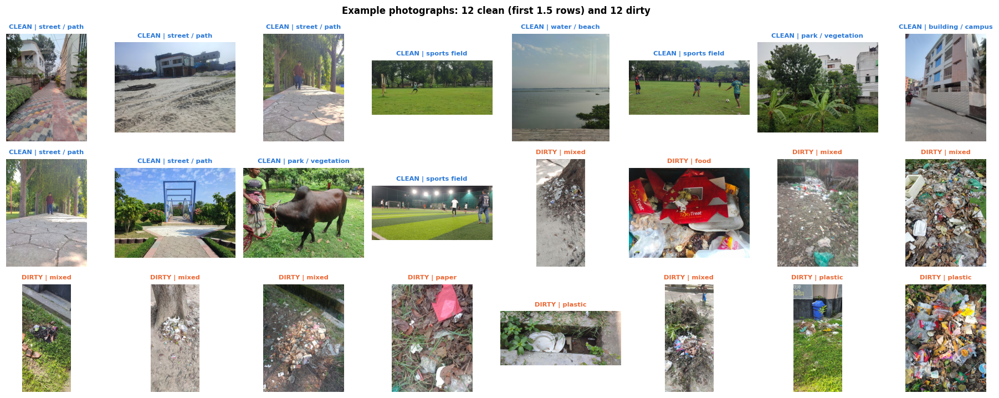

In [5]:
# figure: example photos of both classes
rng = np.random.default_rng(4)
fig, axes = plt.subplots(3, 8, figsize=(17, 6.6))
picks = list(rng.choice(meta[meta.cls == "clean"].file, 12, replace=False)) + list(rng.choice(meta[meta.cls == "dirty"].file, 12, replace=False))
for ax, f in zip(axes.ravel(), picks):
    r = meta.set_index("file").loc[f]
    im = Image.open(D.CACHE / f); ax.imshow(im); ax.axis("off")
    ax.set_title(f"{r.cls.upper()} | {r.scene if r.cls == 'clean' else r.composition}", fontsize=7.5, color=CLS_COL[r.cls])
plt.suptitle("Example photographs: 12 clean (first 1.5 rows) and 12 dirty", fontweight="bold")
plt.tight_layout(); savefig(fig, "fig01_examples.png"); plt.show()

saved -> outputs\figures\fig02_dataset_statistics.png


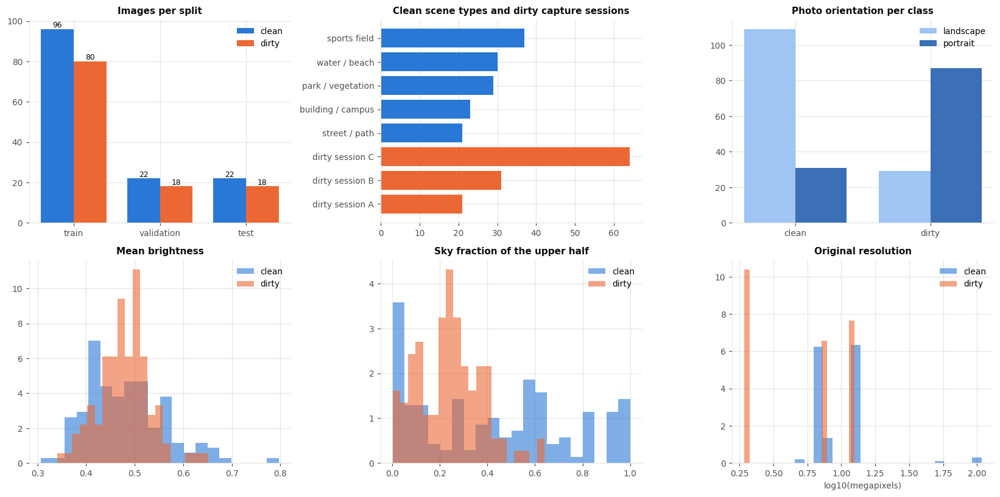

       brightness  sky_fraction
cls                            
clean       0.482         0.433
dirty       0.479         0.241
portrait share: {'clean': 0.221, 'dirty': 0.75}


In [6]:
# figure: dataset statistics and capture differences between the classes
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
ax = axes[0, 0]
ct = pd.crosstab(meta.cls, meta.split)[["train", "val", "test"]]
x = np.arange(3)
for i, c in enumerate(["clean", "dirty"]):
    ax.bar(x + (i - 0.5) * 0.38, ct.loc[c], 0.38, color=CLS_COL[c], label=c)
    for xx, v in zip(x, ct.loc[c]): ax.text(xx + (i - 0.5) * 0.38, v, str(v), ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, ["train", "validation", "test"]); ax.set_title("Images per split"); ax.legend()
ax = axes[0, 1]
sc = meta[meta.cls == "clean"].scene.value_counts(); ds = meta[meta.cls == "dirty"].source.value_counts()
ax.barh(list(sc.index), sc.values, color=CLS_COL["clean"]); ax.barh(list(ds.index), ds.values, color=CLS_COL["dirty"])
ax.set_title("Clean scene types and dirty capture sessions"); ax.invert_yaxis()
ax = axes[0, 2]
ct = pd.crosstab(meta.cls, meta.orientation)
for i, o in enumerate(["landscape", "portrait"]):
    ax.bar(np.arange(2) + (i - 0.5) * 0.38, ct[o], 0.38, color=["#9ec5f4", "#3b6fb6"][i], label=o)
ax.set_xticks([0, 1], ["clean", "dirty"]); ax.set_title("Photo orientation per class"); ax.legend()
for ax, col, t in [(axes[1, 0], "brightness", "Mean brightness"), (axes[1, 1], "sky_fraction", "Sky fraction of the upper half")]:
    for c in ["clean", "dirty"]:
        ax.hist(meta[meta.cls == c][col], bins=20, alpha=0.6, color=CLS_COL[c], label=c, density=True)
    ax.set_title(t); ax.legend()
ax = axes[1, 2]
mp = meta.width * meta.height / 1e6
for c in ["clean", "dirty"]:
    ax.hist(np.log10(mp[meta.cls == c]), bins=20, alpha=0.6, color=CLS_COL[c], label=c, density=True)
ax.set_xlabel("log10(megapixels)"); ax.set_title("Original resolution"); ax.legend()
plt.tight_layout(); savefig(fig, "fig02_dataset_statistics.png"); plt.show()
print(meta.groupby("cls")[["brightness", "sky_fraction"]].mean().round(3))
print("portrait share:", meta.groupby("cls").orientation.apply(lambda s: (s == "portrait").mean()).round(3).to_dict())

## 1.2 Labelling and splitting

The label comes from the folder: **clean = 0, dirty = 1**. Many photos are bursts of almost the same view (for example 34
shots of one football field). If near-duplicates were spread over training and test, the test would measure memory, not
recognition. Photos are therefore grouped before splitting:

* **dirty**: the location groups annotated in Assignment 14 (51 groups);
* **clean**: consecutive photos with ImageNet-feature cosine similarity ≥ 0.5, or any two photos with similarity ≥ 0.8,
  share a group (41 groups).

Whole groups are assigned to **train / validation / test (≈ 70 / 15 / 15 %)**, separately for each class so that the class
balance is the same everywhere. Among the possible splits, the one whose scene types, capture sessions and orientations are
most similar between training and test was chosen (seed 83); only metadata was used for this. A second, **grouped 5-fold
cross-validation** over all 256 photos is used in §5 to get more reliable numbers than 40 test images can give.

---
# 2. How hard is the task? Simple baselines and possible shortcuts

The two classes were photographed in different ways: clean photos are mostly wide views with sky, dirty photos are mostly
close-ups of the ground, and the classes differ in orientation and camera. A classifier could separate them by these
cues instead of by the presence of garbage. Simple logistic-regression baselines on hand-made features, evaluated with the
same grouped 5-fold cross-validation, show how much each cue alone reveals.

In [7]:
%%writefile cd_eval.py
"""Metrics, speed/compute benchmark, corruptions, shortcut tests and occlusion-sensitivity maps (same for all models)."""
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image, ImageFilter
import cd_data as D


def metrics(y, p, thr=0.5):
    """Dirty = positive class."""
    y, yhat = np.asarray(y), (np.asarray(p) >= thr).astype(int)
    tp, tn = int(((yhat == 1) & (y == 1)).sum()), int(((yhat == 0) & (y == 0)).sum())
    fp, fn = int(((yhat == 1) & (y == 0)).sum()), int(((yhat == 0) & (y == 1)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    from sklearn.metrics import roc_auc_score
    auc = roc_auc_score(y, p) if len(set(y)) == 2 else np.nan
    return {"accuracy": (tp + tn) / len(y), "precision": prec, "recall": rec,
            "F1": 2 * prec * rec / (prec + rec) if prec + rec else 0.0,
            "specificity": tn / (tn + fp) if tn + fp else 0.0, "AUC": auc, "TP": tp, "TN": tn, "FP": fp, "FN": fn}


# --------------------------------------------------------------------------------------------- compute
@torch.no_grad()
def benchmark(model, size=224, warmup=10, runs=50, batch=32):
    from torch.utils.flop_counter import FlopCounterMode
    model.eval()
    x1 = torch.randn(1, 3, size, size, device="cuda")
    with FlopCounterMode(display=False) as fc:
        model(x1)
    gflops = fc.get_total_flops() / 2e9                         # multiply-accumulates count as one FLOP-pair -> GMACs
    for _ in range(warmup):
        model(x1)
    torch.cuda.synchronize()
    lat = []
    for _ in range(runs):
        t = time.perf_counter(); model(x1); torch.cuda.synchronize(); lat.append(time.perf_counter() - t)
    xb = torch.randn(batch, 3, size, size, device="cuda")
    for _ in range(3):
        model(xb)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t = time.perf_counter()
    for _ in range(10):
        model(xb)
    torch.cuda.synchronize()
    thr = 10 * batch / (time.perf_counter() - t)
    lat = np.array(lat) * 1000
    return {"GMACs": gflops, "latency_ms": float(lat.mean()), "latency_p95_ms": float(np.percentile(lat, 95)),
            "FPS_bs1": float(1000 / lat.mean()), f"FPS_bs{batch}": float(thr),
            "peak_inference_mem_GB": torch.cuda.max_memory_allocated() / 2**30}


# --------------------------------------------------------------------------------------------- corruptions & shortcuts
def corrupt(kind, sev, seed=0):
    rng = np.random.default_rng(seed)

    def f(im):
        a = np.asarray(im, np.float32)
        if kind == "dark":
            g = [1.6, 2.2, 3.0][sev - 1]
            return Image.fromarray((255 * (a / 255) ** g * [0.8, 0.6, 0.4][sev - 1]).clip(0, 255).astype(np.uint8))
        if kind == "overexposed":
            return Image.fromarray((a * [1.5, 1.9, 2.4][sev - 1] + 20).clip(0, 255).astype(np.uint8))
        if kind == "blur":
            return im.filter(ImageFilter.GaussianBlur([2, 4, 7][sev - 1]))
        if kind == "noise":
            return Image.fromarray((a + rng.normal(0, [12, 25, 40][sev - 1], a.shape)).clip(0, 255).astype(np.uint8))
        if kind == "haze":
            t = [0.35, 0.55, 0.7][sev - 1]
            return Image.fromarray((a * (1 - t) + 215 * t).clip(0, 255).astype(np.uint8))
        if kind == "occlusion":
            out = a.copy(); h, w = a.shape[:2]
            n, s = [3, 5, 8][sev - 1], [0.18, 0.22, 0.26][sev - 1]
            for _ in range(n):
                bw, bh = int(s * w), int(s * h)
                x0, y0 = rng.integers(0, w - bw), rng.integers(0, h - bh)
                out[y0:y0 + bh, x0:x0 + bw] = (128, 128, 128)
            return Image.fromarray(out.astype(np.uint8))
        raise ValueError(kind)
    return f


CORRUPTIONS = ["dark", "overexposed", "blur", "noise", "haze", "occlusion"]


def view_transform(kind):
    """Shortcut tests that change *what part of the scene* is shown.
    bottom: lower half only (removes the sky);  centre: central 50% zoom (close-up of the scene centre);
    top: upper half only (mostly sky / background for wide shots)."""
    def f(im):
        w, h = im.size
        if kind == "bottom":
            return im.crop((0, h // 2, w, h))
        if kind == "top":
            return im.crop((0, 0, w, h // 2))
        if kind == "centre":
            return im.crop((w // 4, h // 4, w - w // 4, h - h // 4))
        raise ValueError(kind)
    return f


def apply_to_cache(cache, files, fn):
    return {f: fn(cache[f]) for f in files}


# --------------------------------------------------------------------------------------------- explanation
@torch.no_grad()
def occlusion_map(model, im, size=224, patch=32, stride=16):
    """Model-agnostic saliency: drop in P(predicted class) when a grey patch hides each region (works for CNN,
    Transformer and Mamba alike)."""
    tf = D.make_transforms(size, train=False)
    x = tf(im)[None].cuda()
    with torch.autocast("cuda", torch.bfloat16):
        p0 = model(x).float().softmax(-1)[0]
    c = int(p0.argmax())
    xs, pos = [], []
    for yy in range(0, size - patch + 1, stride):
        for xx in range(0, size - patch + 1, stride):
            z = x.clone(); z[:, :, yy:yy + patch, xx:xx + patch] = 0.0
            xs.append(z); pos.append((yy, xx))
    drops = []
    for i in range(0, len(xs), 64):
        with torch.autocast("cuda", torch.bfloat16):
            drops.append(p0[c] - model(torch.cat(xs[i:i + 64])).float().softmax(-1)[:, c])
    drops = torch.cat(drops).cpu().numpy()
    heat, cnt = np.zeros((size, size)), np.zeros((size, size))
    for d, (yy, xx) in zip(drops, pos):
        heat[yy:yy + patch, xx:xx + patch] += d; cnt[yy:yy + patch, xx:xx + patch] += 1
    return heat / np.maximum(cnt, 1), c, float(p0[c])


def display_crop(im, size=224):
    """The exact centre crop the models see (for overlaying saliency maps)."""
    s = int(size / 0.875) / min(im.size)
    r = im.resize((round(im.width * s), round(im.height * s)))
    l, t = (r.width - size) // 2, (r.height - size) // 2
    return r.crop((l, t, l + size, t + size))

Overwriting cd_eval.py


In [8]:
import cd_eval as E
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
def colour_hist(f, bins=8):
    a = np.asarray(Image.open(D.CACHE / f).convert("HSV").resize((96, 96)))
    return np.concatenate([np.histogram(a[..., c], bins=bins, range=(0, 255), density=True)[0] for c in range(3)])
FEATS = {
    "orientation + resolution (camera metadata)": np.c_[(meta.orientation == "portrait"), np.log10(meta.width * meta.height),
                                                         meta.width / meta.height],
    "brightness + sky fraction": meta[["brightness", "sky_fraction"]].values,
    "HSV colour histogram (24 bins)": np.stack([colour_hist(f) for f in meta.file]),
}
rows = []
for name, X in FEATS.items():
    p = np.zeros(len(meta))
    for k in range(5):
        tr, te = meta.fold != k, meta.fold == k
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)).fit(X[tr], meta.label[tr])
        p[te] = clf.predict_proba(X[te])[:, 1]
    rows.append({"baseline": name, **{k: v for k, v in E.metrics(meta.label, p).items() if k in ("accuracy", "precision", "recall", "F1", "AUC")}})
BASE = pd.DataFrame(rows).set_index("baseline").round(3)
display(BASE); BASE.to_csv(RES / "baselines.csv")

,accuracy,precision,recall,F1,AUC
baseline,,,,,
orientation + resolution (camera metadata),0.758,0.737,0.724,0.730,0.888
brightness + sky fraction,0.645,0.594,0.681,0.635,0.650
HSV colour histogram (24 bins),0.641,0.574,0.802,0.669,0.659


---
# 3. Backbones

| model | family | checkpoint | ImageNet top-1 | key idea |
|---|---|---|---|---|
| ResNet-50 | CNN | `resnet50.a1_in1k` (timm) | 80.4 | residual bottleneck convolutions |
| ConvNeXt-T | CNN | `convnext_tiny.fb_in1k` | 82.1 | modernised CNN: 7×7 depth-wise conv, LayerNorm, inverted bottleneck |
| ViT-S/16 | Transformer | `vit_small_patch16_224.augreg_in21k_ft_in1k` | 81.4 | global self-attention over 16×16 patches |
| Swin-T | Transformer | `swin_tiny_patch4_window7_224.ms_in1k` | 81.2 | self-attention in shifted local windows, hierarchical |
| MambaVision-T | Mamba | `nvidia/MambaVision-T-1K` | 82.3 | CNN stages 1-2; stages 3-4 mix Mamba (selective state-space) and attention blocks |
| MambaVision-T2 | Mamba | `nvidia/MambaVision-T2-1K` | 82.7 | deeper variant of MambaVision-T |

Each model keeps its pretrained body and gets a new 2-way linear head.

In [9]:
%%writefile cd_models.py
"""Backbones for clean/dirty classification: two CNNs, two Transformers and two Mamba (MambaVision) models.

All are ImageNet-1k classifiers of similar size (22-35 M parameters). Each gets a new 2-way linear head.
MambaVision is loaded from the Hugging Face hub; its selective-scan CUDA kernel is replaced by the pure-PyTorch scan in
third_party/mamba_ssm (identical maths, see that file).
"""
import sys
from pathlib import Path
import torch
import torch.nn as nn

ROOT = Path(__file__).resolve().parent
if str(ROOT / "third_party") not in sys.path:
    sys.path.insert(0, str(ROOT / "third_party"))

MODELS = {
    # name:            (family,        source,  checkpoint)
    "ResNet-50":       ("CNN",         "timm",  "resnet50.a1_in1k"),
    "ConvNeXt-T":      ("CNN",         "timm",  "convnext_tiny.fb_in1k"),
    "ViT-S/16":        ("Transformer", "timm",  "vit_small_patch16_224.augreg_in21k_ft_in1k"),
    "Swin-T":          ("Transformer", "timm",  "swin_tiny_patch4_window7_224.ms_in1k"),
    "MambaVision-T":   ("Mamba",       "hf",    "nvidia/MambaVision-T-1K"),
    "MambaVision-T2":  ("Mamba",       "hf",    "nvidia/MambaVision-T2-1K"),
}
FAMILY = {k: v[0] for k, v in MODELS.items()}


class MambaVisionClassifier(nn.Module):
    def __init__(self, ckpt, num_classes=2):
        super().__init__()
        import warnings
        from transformers import AutoModelForImageClassification
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            hf = AutoModelForImageClassification.from_pretrained(ckpt, trust_remote_code=True)
        self.body = hf.model
        self.body.head = nn.Linear(self.body.head.in_features, num_classes)

    def forward(self, x):
        return self.body(x)

    def head_params(self):
        return list(self.body.head.parameters())


class TimmClassifier(nn.Module):
    def __init__(self, ckpt, num_classes=2, drop_path=0.1):
        super().__init__()
        import timm
        self.net = timm.create_model(ckpt, pretrained=True, num_classes=num_classes, drop_path_rate=drop_path)

    def forward(self, x):
        return self.net(x)

    def head_params(self):
        return list(self.net.get_classifier().parameters())


def build(name, num_classes=2):
    fam, src, ckpt = MODELS[name]
    return MambaVisionClassifier(ckpt, num_classes) if src == "hf" else TimmClassifier(ckpt, num_classes)


def n_params(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable))

Overwriting cd_models.py


In [10]:
import cd_models as M
# check that the pure-PyTorch chunked scan matches the step-by-step reference
from mamba_ssm.ops.selective_scan_interface import selective_scan_fn, selective_scan_ref
g = torch.Generator(device="cuda").manual_seed(0)
b, d, n, L = 4, 320, 16, 196
args = [torch.randn(b, d, L, device="cuda", generator=g), torch.randn(b, d, L, device="cuda", generator=g),
        -torch.rand(d, n, device="cuda", generator=g) * 5, torch.randn(b, n, L, device="cuda", generator=g),
        torch.randn(b, n, L, device="cuda", generator=g), torch.randn(d, device="cuda", generator=g)]
y_ref = selective_scan_ref(*args, delta_softplus=True); y_fast = selective_scan_fn(*args, delta_softplus=True)
print(f"chunked scan vs reference: max relative error {((y_ref - y_fast).abs().max() / y_ref.abs().max()).item():.2e}")
ARCH = pd.DataFrame([{"model": m, "family": M.FAMILY[m], "checkpoint": M.MODELS[m][2],
                      "params (M)": M.n_params(M.build(m)) / 1e6} for m in MODELS]).set_index("model").round(2)
display(ARCH); ARCH.to_csv(RES / "architectures.csv")

chunked scan vs reference: max relative error 1.55e-06


,family,checkpoint,params (M)
model,,,
ResNet-50,CNN,resnet50.a1_in1k,23.51
ConvNeXt-T,CNN,convnext_tiny.fb_in1k,27.82
ViT-S/16,Transformer,vit_small_patch16_224.augreg_in21k_ft_in1k,21.67
Swin-T,Transformer,swin_tiny_patch4_window7_224.ms_in1k,27.52
MambaVision-T,Mamba,nvidia/MambaVision-T-1K,31.15
MambaVision-T2,Mamba,nvidia/MambaVision-T2-1K,34.46


---
# 4. Fine-tuning on the train / validation / test split

Identical recipe for every backbone:

| setting | value |
|---|---|
| input | 224 × 224; train: random-resized crop (scale 0.35-1), flip, colour jitter, blur, grey-scale, random erasing; test: resize + centre crop |
| optimiser | AdamW, lr 1e-4 (body) / 1e-3 (new head), weight decay 0.05, cosine schedule, 2 warm-up epochs |
| epochs / batch | 25 / 16 |
| loss | class-weighted cross-entropy, label smoothing 0.1 |
| precision | bfloat16 autocast |
| model selection | lowest validation loss |
| seeds | 0, 1, 2 |

The centre crop at test time removes most of the orientation / aspect-ratio difference between the classes.

In [11]:
%%writefile cd_train.py
"""Fine-tuning and evaluation loop shared by all backbones (identical recipe for every model). Resumable: a finished
run is skipped and its saved predictions are returned."""
import json, time, math, random
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import cd_data as D
import cd_models as M

ROOT = Path(__file__).resolve().parent
RUNS = ROOT / "outputs" / "runs"

DEFAULT = dict(epochs=25, batch=16, lr=1e-4, head_lr=1e-3, weight_decay=0.05, warmup=2, label_smoothing=0.1,
               size=224, aug="standard", freeze_backbone=False, amp=True, seed=0)


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


@torch.no_grad()
def predict(model, files, cache, size=224, bs=32, transform=None):
    """Returns P(dirty) for every file (test-time transform = resize + centre crop unless given)."""
    model.eval()
    tf = transform or D.make_transforms(size, train=False)
    out = []
    for i in range(0, len(files), bs):
        x = torch.stack([tf(cache[f]) for f in files[i:i + bs]]).cuda()
        with torch.autocast("cuda", torch.bfloat16):
            out.append(model(x).float().softmax(-1)[:, 1].cpu())
    return torch.cat(out).numpy()


def train_run(name, model_name, train_files, train_labels, val_files, val_labels, cache, cfg=None, eval_sets=None,
              log=print, save_weights=False):
    """eval_sets: {tag: list_of_files}; their P(dirty) under the best checkpoint is saved with the run."""
    cfg = {**DEFAULT, **(cfg or {})}
    out = RUNS / name
    if (out / "result.json").exists():
        return json.loads((out / "result.json").read_text())
    out.mkdir(parents=True, exist_ok=True)
    set_seed(cfg["seed"])
    model = M.build(model_name).cuda()
    head = set(id(p) for p in model.head_params())
    if cfg["freeze_backbone"]:
        for p in model.parameters():
            if id(p) not in head:
                p.requires_grad_(False)
    groups = [{"params": [p for p in model.parameters() if id(p) in head], "lr": cfg["head_lr"]}]
    body = [p for p in model.parameters() if id(p) not in head and p.requires_grad]
    if body:
        groups.append({"params": body, "lr": cfg["lr"]})
    opt = torch.optim.AdamW(groups, weight_decay=cfg["weight_decay"])
    tr = D.ImageSet(train_files, train_labels, D.make_transforms(cfg["size"], True, cfg["aug"]), cache)
    g = torch.Generator(); g.manual_seed(cfg["seed"])
    dl = torch.utils.data.DataLoader(tr, batch_size=cfg["batch"], shuffle=True, num_workers=0, drop_last=True, generator=g)
    steps = cfg["epochs"] * len(dl)
    warm = cfg["warmup"] * len(dl)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, steps - warm))))
    # class weights: the classes are slightly imbalanced (140 clean / 116 dirty)
    w = torch.tensor([len(train_labels) / (2 * (np.array(train_labels) == c).sum()) for c in (0, 1)], dtype=torch.float32).cuda()
    hist, best, best_state = [], (1e9, -1), None
    torch.cuda.reset_peak_memory_stats()
    t_train = 0.0
    for ep in range(cfg["epochs"]):
        model.train()
        t0, losses, correct, n = time.time(), [], 0, 0
        for x, y in dl:
            x, y = x.cuda(non_blocking=True), y.cuda(non_blocking=True)
            with torch.autocast("cuda", torch.bfloat16, enabled=cfg["amp"]):
                logits = model(x).float()
            loss = F.cross_entropy(logits, y, weight=w, label_smoothing=cfg["label_smoothing"])
            opt.zero_grad(set_to_none=True); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            losses.append(loss.item()); correct += (logits.argmax(-1) == y).sum().item(); n += len(y)
        torch.cuda.synchronize(); t_train += time.time() - t0
        pv = predict(model, val_files, cache, cfg["size"])
        yv = np.array(val_labels)
        vloss = float(F.binary_cross_entropy(torch.tensor(pv).clamp(1e-6, 1 - 1e-6), torch.tensor(yv, dtype=torch.float32)))
        vacc = float(((pv >= 0.5) == yv).mean())
        hist.append({"epoch": ep + 1, "train_loss": float(np.mean(losses)), "train_acc": correct / n,
                     "val_loss": vloss, "val_acc": vacc, "epoch_time": time.time() - t0})
        if (vloss, -vacc) < (best[0], -best[1]):                       # model selection: lowest validation loss
            best = (vloss, vacc)
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            hist[-1]["best"] = 1
    model.load_state_dict(best_state)
    res = {"model": model_name, "cfg": cfg, "train_time_s": t_train, "best_val_loss": best[0], "best_val_acc": best[1],
           "peak_train_mem_GB": torch.cuda.max_memory_allocated() / 2**30,
           "params": M.n_params(model), "trainable": M.n_params(model, trainable=True), "history": hist,
           "preds": {}}
    tf = D.make_transforms(cfg["size"], train=False)
    for tag, spec in (eval_sets or {}).items():          # spec = files  or  (files, PIL->PIL function)
        files, fn = (spec, None) if not isinstance(spec, tuple) else spec
        src = cache if fn is None else {f: fn(cache[f]) for f in files}
        res["preds"][tag] = dict(zip(files, predict(model, files, src, cfg["size"], transform=tf).tolist()))
    if save_weights:
        torch.save(model.state_dict(), out / "best.pt")
    (out / "result.json").write_text(json.dumps(res))
    del model, opt
    torch.cuda.empty_cache()
    return res


def load_trained(name, model_name):
    m = M.build(model_name).cuda()
    m.load_state_dict(torch.load(RUNS / name / "best.pt", map_location="cpu", weights_only=False))
    return m.eval()

Overwriting cd_train.py


In [12]:
import cd_train as T, cd_eval as E
CACHE = D.load_cache(meta.file)
SEEDS = [0, 1, 2]
RUN = {}
t0 = time.time()
for m in MODELS:
    for s in SEEDS:
        RUN[(m, s)] = T.train_run(f"split_{tag(m)}_s{s}", m, TRAIN.file, TRAIN.label, VAL.file, VAL.label, CACHE,
                                  {"seed": s}, eval_sets={"test": TEST.file.tolist(), "val": VAL.file.tolist()},
                                  save_weights=(s == 0))
print(f"done in {(time.time() - t0) / 60:.1f} min")
rows = []
for (m, s), r in RUN.items():
    p = np.array([r["preds"]["test"][f] for f in TEST.file])
    rows.append({"model": m, "family": M.FAMILY[m], "seed": s, **E.metrics(TEST.label, p),
                 "train time (s)": r["train_time_s"], "best epoch": [h["epoch"] for h in r["history"] if h.get("best")][-1]})
SPLIT = pd.DataFrame(rows); SPLIT.to_csv(RES / "test_metrics_per_seed.csv", index=False)
agg = SPLIT.groupby("model")[["accuracy", "precision", "recall", "F1", "specificity", "AUC"]].agg(["mean", "std"]).loc[MODELS]
display(agg.round(3)); agg.round(4).to_csv(RES / "test_metrics_mean_std.csv")

done in 0.0 min


accuracy        precision        recall          F1         \
                   mean    std      mean    std   mean  std   mean    std   
model                                                                       
ResNet-50         0.958  0.014     0.916  0.027    1.0  0.0  0.956  0.015   
ConvNeXt-T        0.958  0.029     0.917  0.052    1.0  0.0  0.956  0.029   
ViT-S/16          0.967  0.029     0.933  0.058    1.0  0.0  0.965  0.030   
Swin-T            0.958  0.029     0.917  0.052    1.0  0.0  0.956  0.029   
MambaVision-T     0.950  0.025     0.902  0.045    1.0  0.0  0.948  0.025   
MambaVision-T2    0.958  0.014     0.916  0.027    1.0  0.0  0.956  0.015   

               specificity           AUC         
                      mean    std   mean    std  
model                                            
ResNet-50            0.924  0.026  1.000  0.000  
ConvNeXt-T           0.924  0.052  1.000  0.000  
ViT-S/16             0.939  0.052  0.992  0.013  
Swin-T               0.924  0.052  1.000  0.000  
MambaVision-T        0.909  0.045  1.000  0.000  
MambaVision-T2       0.924  0.026  1.000  0.000

saved -> outputs\figures\fig03_training_curves.png


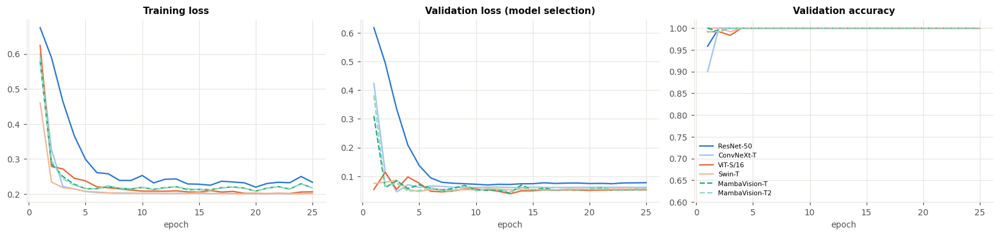

In [13]:
# training curves (mean of 3 seeds)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for m in MODELS:
    H = [pd.DataFrame(RUN[(m, s)]["history"]) for s in SEEDS]
    e = H[0].epoch
    for ax, k in zip(axes, ["train_loss", "val_loss", "val_acc"]):
        v = np.stack([h[k].values for h in H])
        ax.plot(e, v.mean(0), color=COL[m], label=m, ls="-" if M.FAMILY[m] != "Mamba" else "--")
for ax, t in zip(axes, ["Training loss", "Validation loss (model selection)", "Validation accuracy"]):
    ax.set_title(t); ax.set_xlabel("epoch")
axes[2].legend(fontsize=7); axes[2].set_ylim(0.6, 1.02)
plt.tight_layout(); savefig(fig, "fig03_training_curves.png"); plt.show()

saved -> outputs\figures\fig04_confusion_split.png


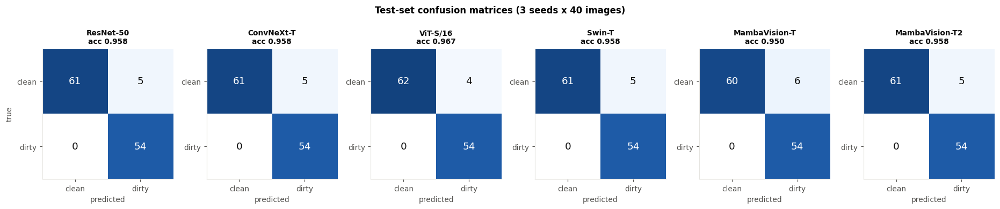

In [14]:
# confusion matrices on the 40 test images, summed over the 3 seeds (120 predictions per model)
from matplotlib.colors import LinearSegmentedColormap
BLUE = LinearSegmentedColormap.from_list("b", ["#ffffff", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
fig, axes = plt.subplots(1, 6, figsize=(17, 3.2))
for ax, m in zip(axes, MODELS):
    S = SPLIT[SPLIT.model == m][["TN", "FP", "FN", "TP"]].sum()
    cm = np.array([[S.TN, S.FP], [S.FN, S.TP]])
    ax.imshow(cm, cmap=BLUE, vmin=0, vmax=cm.sum(1).max()); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=12, color="white" if cm[i, j] > cm.max() / 2 else INK)
    ax.set_xticks([0, 1], ["clean", "dirty"]); ax.set_yticks([0, 1], ["clean", "dirty"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true") if m == MODELS[0] else None
    acc = (cm[0, 0] + cm[1, 1]) / cm.sum(); ax.set_title(f"{m}\nacc {acc:.3f}", fontsize=9)
plt.suptitle("Test-set confusion matrices (3 seeds x 40 images)", fontweight="bold", y=1.04)
plt.tight_layout(); savefig(fig, "fig04_confusion_split.png"); plt.show()

---
# 5. Grouped 5-fold cross-validation

40 test images give a coarse estimate: one mistake costs 2.5 % accuracy. Every model is therefore also trained five times,
each time holding out one of five grouped folds (the next fold is used for validation). Every one of the 256 photos is
then predicted exactly once by a model that never saw it or its near-duplicates. The same runs also predict
degraded and cropped versions of their held-out photos, which §8 and §9 use.

In [15]:
VIEWS = ["bottom", "top", "centre"]
CV = {}
t0 = time.time()
for m in MODELS:
    for k in range(5):
        te = meta[meta.fold == k]; va = meta[meta.fold == (k + 1) % 5]; tr = meta[(meta.fold != k) & (meta.fold != (k + 1) % 5)]
        ev = {"test": te.file.tolist()}
        for c in E.CORRUPTIONS:
            for sev in (1, 2, 3):
                ev[f"{c}_{sev}"] = (te.file.tolist(), E.corrupt(c, sev, seed=sev))
        for v in VIEWS:
            ev[f"view_{v}"] = (te.file.tolist(), E.view_transform(v))
        CV[(m, k)] = T.train_run(f"cv_{tag(m)}_f{k}", m, tr.file, tr.label, va.file, va.label, CACHE, {"seed": 0}, eval_sets=ev)
print(f"done in {(time.time() - t0) / 60:.1f} min")

def oof(m, key="test"):
    # out-of-fold P(dirty) for all 256 photos
    d = {}
    for k in range(5):
        d.update(CV[(m, k)]["preds"][key])
    return np.array([d[f] for f in meta.file])
OOF = pd.DataFrame({m: oof(m) for m in MODELS}, index=meta.file)
OOF.to_csv(RES / "cv_out_of_fold_p_dirty.csv")
rows = []
for m in MODELS:
    fold_acc = [E.metrics(meta.label[meta.fold == k], OOF[m].values[meta.fold == k])["accuracy"] for k in range(5)]
    rows.append({"model": m, "family": M.FAMILY[m], **E.metrics(meta.label, OOF[m].values), "fold acc std": np.std(fold_acc)})
CVM = pd.DataFrame(rows).set_index("model").round(4); display(CVM); CVM.to_csv(RES / "cv_metrics.csv")

done in 0.0 min


,family,accuracy,precision,recall,F1,specificity,AUC,TP,TN,FP,FN,fold acc std
model,,,,,,,,,,,,
ResNet-50,CNN,0.9805,0.9587,1.0,0.9789,0.9643,0.9999,116,135,5,0,0.0408
ConvNeXt-T,CNN,0.9961,0.9915,1.0,0.9957,0.9929,1.0000,116,139,1,0,0.0082
ViT-S/16,Transformer,0.9883,0.9748,1.0,0.9872,0.9786,0.9938,116,137,3,0,0.0245
Swin-T,Transformer,0.9922,0.9831,1.0,0.9915,0.9857,0.9998,116,138,2,0,0.0163
MambaVision-T,Mamba,0.9883,0.9748,1.0,0.9872,0.9786,0.9994,116,137,3,0,0.0163
MambaVision-T2,Mamba,0.9844,0.9667,1.0,0.9831,0.9714,0.9985,116,136,4,0,0.0150


saved ->

 outputs\figures\fig05_confusion_cv.png


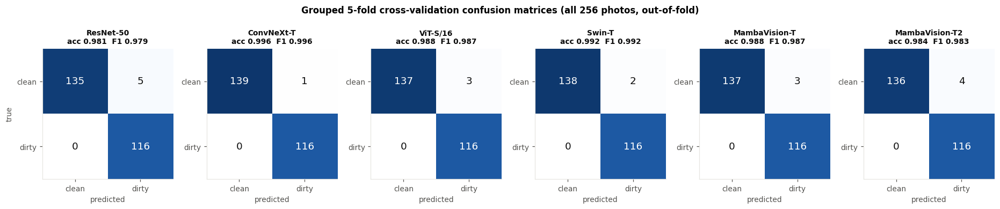

saved -> outputs\figures\fig06_cv_metrics.png


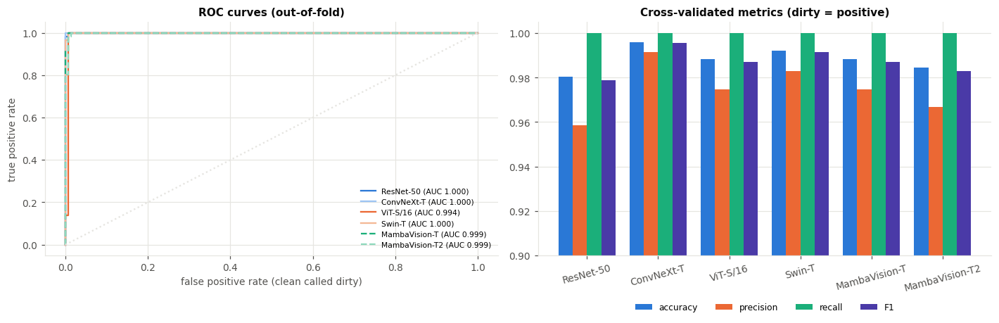

In [16]:
fig, axes = plt.subplots(1, 6, figsize=(17, 3.2))
for ax, m in zip(axes, MODELS):
    r = CVM.loc[m]; cm = np.array([[r.TN, r.FP], [r.FN, r.TP]])
    ax.imshow(cm, cmap=BLUE, vmin=0, vmax=140); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=12, color="white" if cm[i, j] > 70 else INK)
    ax.set_xticks([0, 1], ["clean", "dirty"]); ax.set_yticks([0, 1], ["clean", "dirty"]); ax.set_xlabel("predicted")
    ax.set_title(f"{m}\nacc {r.accuracy:.3f}  F1 {r.F1:.3f}", fontsize=9)
axes[0].set_ylabel("true")
plt.suptitle("Grouped 5-fold cross-validation confusion matrices (all 256 photos, out-of-fold)", fontweight="bold", y=1.04)
plt.tight_layout(); savefig(fig, "fig05_confusion_cv.png"); plt.show()

from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
for m in MODELS:
    fpr, tpr, _ = roc_curve(meta.label, OOF[m]); ax.plot(fpr, tpr, color=COL[m], ls="-" if M.FAMILY[m] != "Mamba" else "--",
                                                         label=f"{m} (AUC {CVM.loc[m, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=GRIDC, ls=":"); ax.set_xlabel("false positive rate (clean called dirty)"); ax.set_ylabel("true positive rate")
ax.set_title("ROC curves (out-of-fold)"); ax.legend(fontsize=7)
ax = axes[1]
x = np.arange(len(MODELS)); mets = ["accuracy", "precision", "recall", "F1"]
for i, k in enumerate(mets):
    ax.bar(x + (i - 1.5) * 0.2, CVM.loc[MODELS, k], 0.2, color=PALETTE[[0, 1, 2, 6][i]], label=k)
ax.set_xticks(x, MODELS, rotation=15); ax.set_ylim(0.9, 1.005); ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17))
ax.set_title("Cross-validated metrics (dirty = positive)")
plt.tight_layout(); savefig(fig, "fig06_cv_metrics.png"); plt.show()

---
# 6. Computational requirements and inference speed

Measured on the same GPU with the seed-0 models: parameters, multiply-accumulate operations (GMACs) for one 224 × 224
image, latency for one image (batch 1, mean of 50 runs after 10 warm-up runs), throughput at batch 32, peak inference
memory, and training time and memory from §4.

In [17]:
SPEED = {}
for m in MODELS:
    net = T.load_trained(f"split_{tag(m)}_s0", m)
    with torch.autocast("cuda", torch.bfloat16):
        SPEED[m] = E.benchmark(net)
    SPEED[m]["params (M)"] = M.n_params(net) / 1e6
    del net; torch.cuda.empty_cache()
COMP = pd.DataFrame(SPEED).T
tt = SPLIT.groupby("model")["train time (s)"].mean()
COMP["train time 25 ep (s)"] = tt
COMP["peak train mem (GB)"] = pd.Series({m: np.mean([RUN[(m, s)]["peak_train_mem_GB"] for s in SEEDS]) for m in MODELS})
COMP = COMP.loc[MODELS].round(2); display(COMP); COMP.to_csv(RES / "compute.csv")

,GMACs,latency_ms,latency_p95_ms,FPS_bs1,FPS_bs32,peak_inference_mem_GB,params (M),train time 25 ep (s),peak train mem (GB)
ResNet-50,4.09,7.41,8.86,135.01,2823.25,0.34,23.51,22.61,1.25
ConvNeXt-T,4.45,5.24,6.06,190.75,2882.45,0.44,27.82,22.84,1.64
ViT-S/16,4.60,5.12,7.10,195.15,4684.27,0.23,21.67,21.88,1.09
Swin-T,4.49,9.04,9.31,110.57,2107.84,0.56,27.52,25.90,1.76
MambaVision-T,4.60,30.66,32.31,32.62,378.23,1.22,31.15,51.25,5.06
MambaVision-T2,5.29,41.66,43.10,24.00,272.20,1.24,34.46,65.92,6.69


saved -> outputs\figures\fig07_compute.png


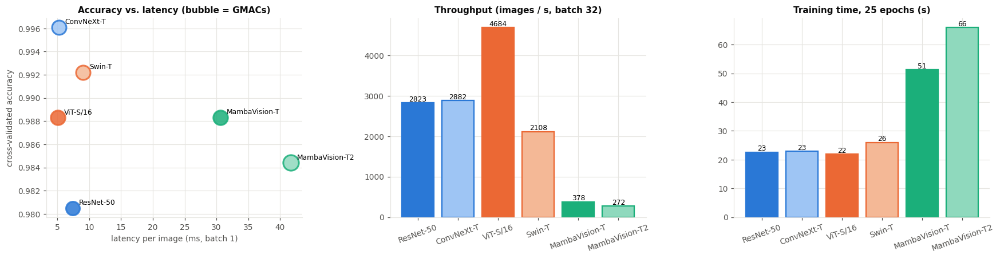

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
ax = axes[0]
for m in MODELS:
    ax.scatter(COMP.loc[m, "latency_ms"], CVM.loc[m, "accuracy"], s=COMP.loc[m, "GMACs"] * 60, color=COL[m], alpha=0.85,
               edgecolor=FAMILY_COL[M.FAMILY[m]], lw=2)
    ax.annotate(m, (COMP.loc[m, "latency_ms"], CVM.loc[m, "accuracy"]), xytext=(7, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("latency per image (ms, batch 1)"); ax.set_ylabel("cross-validated accuracy"); ax.set_title("Accuracy vs. latency (bubble = GMACs)")
for ax, col, t in [(axes[1], "FPS_bs32", "Throughput (images / s, batch 32)"), (axes[2], "train time 25 ep (s)", "Training time, 25 epochs (s)")]:
    ax.bar(range(6), COMP[col], color=[COL[m] for m in MODELS], edgecolor=[FAMILY_COL[M.FAMILY[m]] for m in MODELS], lw=1.5)
    ax.set_xticks(range(6), MODELS, rotation=20); ax.set_title(t)
    for i, v in enumerate(COMP[col]): ax.text(i, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); savefig(fig, "fig07_compute.png"); plt.show()

---
# 7. Training configurations: frozen backbone and fewer training images

* **Linear probe**: the pretrained body is frozen and only the new head is trained. This shows how good each family's ImageNet
  features already are for this task, and how much fine-tuning adds.
* **Data efficiency**: full fine-tuning with only 10 %, 25 % or 50 % of the training images (random, class-balanced, 3 seeds),
  to see which family needs the least data.

Both use the train / validation / test split of §4.

accuracy     F1  AUC  \
model          setting                                            
ResNet-50      linear probe (frozen body)     0.950  0.947  1.0   
               full fine-tuning               0.950  0.947  1.0   
ConvNeXt-T     linear probe (frozen body)     0.950  0.947  1.0   
               full fine-tuning               0.975  0.973  1.0   
ViT-S/16       linear probe (frozen body)     0.950  0.947  1.0   
               full fine-tuning               0.950  0.947  1.0   
Swin-T         linear probe (frozen body)     0.975  0.973  1.0   
               full fine-tuning               0.975  0.973  1.0   
MambaVision-T  linear probe (frozen body)     0.925  0.923  1.0   
               full fine-tuning               0.925  0.923  1.0   
MambaVision-T2 linear probe (frozen body)     0.950  0.947  1.0   
               full fine-tuning               0.950  0.947  1.0   

                                           trainable (M)  train time (s)  \
model          setting                                                     
ResNet-50      linear probe (frozen body)          0.004          17.745   
               full fine-tuning                   23.512          22.902   
ConvNeXt-T     linear probe (frozen body)          0.002          17.353   
               full fine-tuning                   27.822          22.788   
ViT-S/16       linear probe (frozen body)          0.001          17.414   
               full fine-tuning                   21.666          21.874   
Swin-T         linear probe (frozen body)          0.002          18.657   
               full fine-tuning                   27.521          26.261   
MambaVision-T  linear probe (frozen body)          0.001          28.328   
               full fine-tuning                   31.155          51.275   
MambaVision-T2 linear probe (frozen body)          0.001          33.306   
               full fine-tuning                   34.464          66.393   

                                           train mem (GB)  
model          setting                                     
ResNet-50      linear probe (frozen body)           0.410  
               full fine-tuning                     1.189  
ConvNeXt-T     linear probe (frozen body)           0.508  
               full fine-tuning                     1.644  
ViT-S/16       linear probe (frozen body)           0.283  
               full fine-tuning                     1.092  
Swin-T         linear probe (frozen body)           0.627  
               full fine-tuning                     1.761  
MambaVision-T  linear probe (frozen body)           1.293  
               full fine-tuning                     5.060  
MambaVision-T2 linear probe (frozen body)           1.317  
               full fine-tuning                     6.752

model,ResNet-50,ConvNeXt-T,ViT-S/16,Swin-T,MambaVision-T,MambaVision-T2
fraction,,,,,,
0.10,0.975,0.917,0.958,0.967,0.925,0.925
0.25,0.942,0.942,0.958,0.933,0.933,0.925
0.50,0.950,0.950,0.967,0.975,0.933,0.958
1.00,0.958,0.958,0.967,0.958,0.950,0.958


saved -> outputs\figures\fig08_probe_and_data_efficiency.png


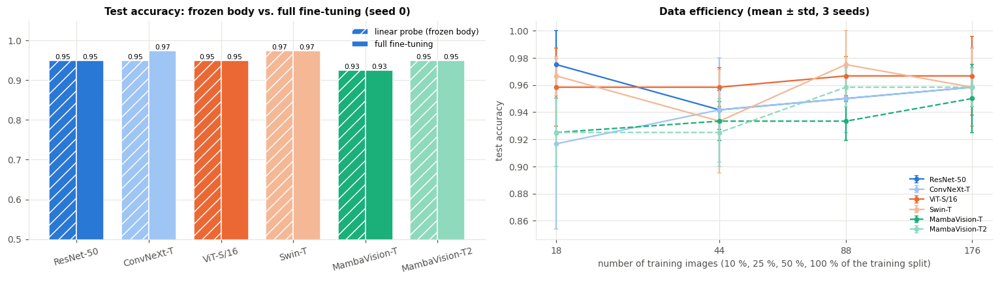

In [19]:
rows = []
for m in MODELS:
    r = T.train_run(f"probe_{tag(m)}_s0", m, TRAIN.file, TRAIN.label, VAL.file, VAL.label, CACHE,
                    {"seed": 0, "freeze_backbone": True}, eval_sets={"test": TEST.file.tolist()})
    p = np.array([r["preds"]["test"][f] for f in TEST.file])
    rows.append({"model": m, "setting": "linear probe (frozen body)", **E.metrics(TEST.label, p), "trainable (M)": r["trainable"] / 1e6,
                 "train time (s)": r["train_time_s"], "train mem (GB)": r["peak_train_mem_GB"]})
    s0 = SPLIT[(SPLIT.model == m) & (SPLIT.seed == 0)].iloc[0]
    rows.append({"model": m, "setting": "full fine-tuning", **{k: s0[k] for k in ("accuracy", "precision", "recall", "F1", "AUC")},
                 "trainable (M)": RUN[(m, 0)]["trainable"] / 1e6, "train time (s)": RUN[(m, 0)]["train_time_s"],
                 "train mem (GB)": RUN[(m, 0)]["peak_train_mem_GB"]})
PROBE = pd.DataFrame(rows).set_index(["model", "setting"])[["accuracy", "F1", "AUC", "trainable (M)", "train time (s)", "train mem (GB)"]].round(3)
display(PROBE); PROBE.to_csv(RES / "linear_probe_vs_finetune.csv")

FRACS = [0.1, 0.25, 0.5]
rows = []
for frac in FRACS:
    for s in SEEDS:
        sub = TRAIN.groupby("cls", group_keys=False).apply(lambda g: g.sample(max(2, round(frac * len(g))), random_state=s))
        for m in MODELS:
            r = T.train_run(f"frac{int(frac * 100)}_{tag(m)}_s{s}", m, sub.file, sub.label, VAL.file, VAL.label, CACHE,
                            {"seed": s}, eval_sets={"test": TEST.file.tolist()})
            p = np.array([r["preds"]["test"][f] for f in TEST.file])
            rows.append({"model": m, "fraction": frac, "n_train": len(sub), "seed": s, **E.metrics(TEST.label, p)})
for _, r in SPLIT.iterrows():
    rows.append({"model": r.model, "fraction": 1.0, "n_train": len(TRAIN), "seed": r.seed, **{k: r[k] for k in ("accuracy", "F1", "AUC")}})
EFF = pd.DataFrame(rows); EFF.to_csv(RES / "data_efficiency.csv", index=False)
effm = EFF.pivot_table(index="fraction", columns="model", values="accuracy", aggfunc="mean")[MODELS].round(3)
display(effm)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ax = axes[0]
pr = PROBE.reset_index()
x = np.arange(6)
for i, (st, hatch) in enumerate([("linear probe (frozen body)", "//"), ("full fine-tuning", None)]):
    v = pr[pr.setting == st].set_index("model").loc[MODELS, "accuracy"]
    ax.bar(x + (i - 0.5) * 0.38, v, 0.38, color=[COL[m] for m in MODELS], hatch=hatch, edgecolor="white", label=st)
    for xx, vv in zip(x, v): ax.text(xx + (i - 0.5) * 0.38, vv, f"{vv:.2f}", ha="center", va="bottom", fontsize=7)
ax.set_xticks(x, MODELS, rotation=15); ax.set_ylim(0.5, 1.05); ax.set_title("Test accuracy: frozen body vs. full fine-tuning (seed 0)"); ax.legend(fontsize=8)
ax = axes[1]
for m in MODELS:
    g = EFF[EFF.model == m].groupby("n_train").accuracy.agg(["mean", "std"])
    ax.errorbar(g.index, g["mean"], yerr=g["std"], color=COL[m], marker="o", ms=4, capsize=2, label=m,
                ls="-" if M.FAMILY[m] != "Mamba" else "--")
ax.set_xscale("log"); ax.set_xticks(sorted(EFF.n_train.unique()), [str(v) for v in sorted(EFF.n_train.unique())]); ax.minorticks_off()
ax.set_xlabel("number of training images (10 %, 25 %, 50 %, 100 % of the training split)"); ax.set_ylabel("test accuracy"); ax.set_title("Data efficiency (mean ± std, 3 seeds)")
ax.legend(fontsize=7)
plt.tight_layout(); savefig(fig, "fig08_probe_and_data_efficiency.png"); plt.show()

---
# 8. Robustness and shortcut tests

**(a) Corruptions.** The held-out photos of every cross-validation fold are degraded (dark, overexposed, blur, noise, haze,
grey occluding patches; 3 severities) and classified by the fold's model.

**(b) What part of the scene matters?** The same photos are cropped to their **bottom half** (ground only, no sky), their
**top half**, or their **centre** (a 2× zoom). If a model has learned "garbage = dirty", the bottom-half and centre crops of
dirty photos should still be called dirty and those of clean photos clean. If it has learned "close-up of the ground =
dirty", clean photos cropped to the ground will be called dirty.

In [20]:
rows = []
for m in MODELS:
    for c in E.CORRUPTIONS:
        for sev in (1, 2, 3):
            p = oof(m, f"{c}_{sev}"); rows.append({"model": m, "condition": c, "severity": sev, **E.metrics(meta.label, p)})
    for v in VIEWS:
        p = oof(m, f"view_{v}"); r = E.metrics(meta.label, p)
        rows.append({"model": m, "condition": f"view: {v}", "severity": 0, **r,
                     "clean called dirty": r["FP"] / (r["FP"] + r["TN"]), "dirty called clean": r["FN"] / (r["FN"] + r["TP"])})
ROB = pd.DataFrame(rows); ROB.to_csv(RES / "robustness.csv", index=False)
cor = ROB[ROB.severity > 0].pivot_table(index="model", columns="condition", values="accuracy", aggfunc="mean").loc[MODELS]
cor.insert(0, "clean", CVM.loc[MODELS, "accuracy"]); cor["mean of 6"] = cor[E.CORRUPTIONS].mean(1)
display(cor.round(3)); cor.round(4).to_csv(RES / "robustness_summary.csv")
vw = ROB[ROB.severity == 0].set_index(["model", "condition"])[["accuracy", "clean called dirty", "dirty called clean"]]
vw = vw.unstack("condition").loc[MODELS]
display(vw.round(3)); vw.round(4).to_csv(RES / "view_tests.csv")

condition,clean,blur,dark,haze,noise,occlusion,overexposed,mean of 6
model,,,,,,,,
ResNet-50,0.980,0.944,0.974,0.990,0.966,0.975,0.977,0.971
ConvNeXt-T,0.996,0.958,0.996,1.000,0.997,1.000,0.992,0.991
ViT-S/16,0.988,0.970,0.943,0.974,0.980,0.990,0.944,0.967
Swin-T,0.992,0.954,0.988,0.990,0.988,0.990,0.987,0.983
MambaVision-T,0.988,0.952,0.984,0.986,0.874,0.990,0.987,0.962
MambaVision-T2,0.984,0.906,0.969,0.982,0.911,0.987,0.983,0.956


accuracy                        clean called dirty  \
condition      view: bottom view: centre view: top       view: bottom   
model                                                                   
ResNet-50             0.945        0.961     0.965              0.093   
ConvNeXt-T            0.984        0.996     0.996              0.021   
ViT-S/16              0.934        0.977     0.973              0.093   
Swin-T                0.906        0.984     0.984              0.164   
MambaVision-T         0.941        0.980     0.988              0.100   
MambaVision-T2        0.930        0.969     0.984              0.107   

                                      dirty called clean               \
condition      view: centre view: top       view: bottom view: centre   
model                                                                   
ResNet-50             0.071     0.043              0.009        0.000   
ConvNeXt-T            0.007     0.000              0.009        0.000   
ViT-S/16              0.043     0.029              0.034        0.000   
Swin-T                0.021     0.007              0.009        0.009   
MambaVision-T         0.029     0.014              0.009        0.009   
MambaVision-T2        0.043     0.014              0.026        0.017   

                          
condition      view: top  
model                     
ResNet-50          0.026  
ConvNeXt-T         0.009  
ViT-S/16           0.026  
Swin-T             0.026  
MambaVision-T      0.009  
MambaVision-T2     0.017

saved -> outputs\figures\fig09_robustness.png


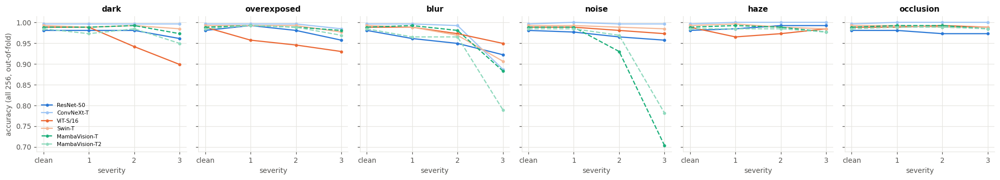

saved -> outputs\figures\fig10_view_tests.png


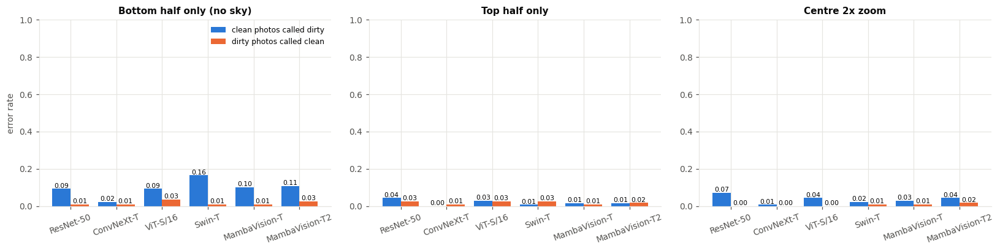

saved -> outputs\figures\fig11_view_examples.png


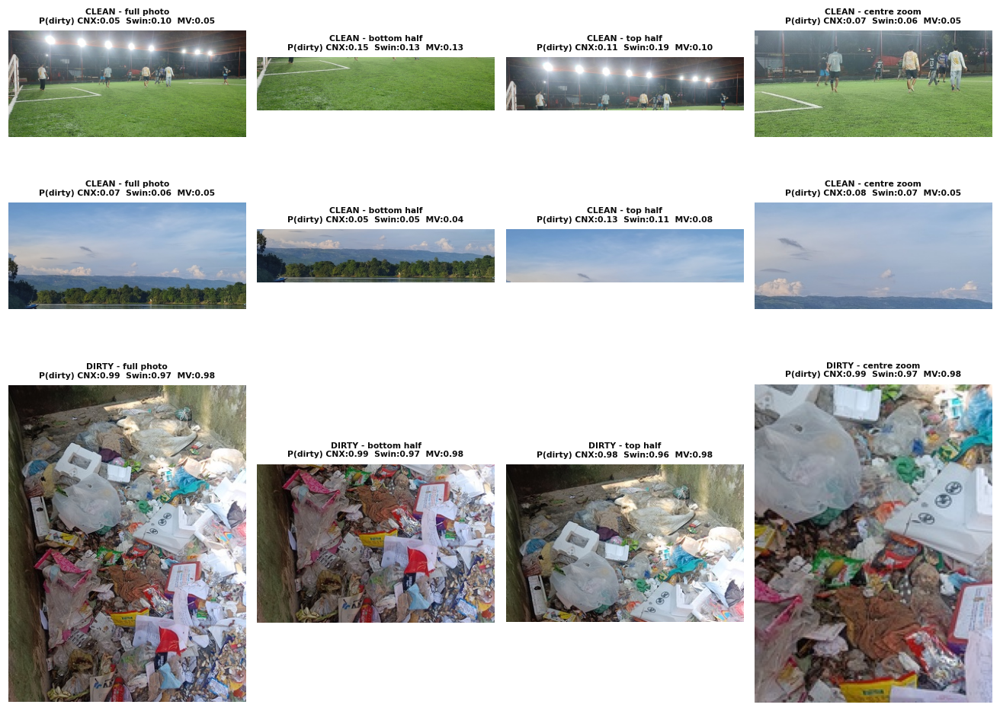

In [21]:
fig, axes = plt.subplots(1, 6, figsize=(18, 3.3), sharey=True)
for ax, c in zip(axes, E.CORRUPTIONS):
    for m in MODELS:
        y = [CVM.loc[m, "accuracy"]] + [ROB[(ROB.model == m) & (ROB.condition == c) & (ROB.severity == s)].accuracy.iloc[0] for s in (1, 2, 3)]
        ax.plot(range(4), y, "-o", ms=3, color=COL[m], ls="-" if M.FAMILY[m] != "Mamba" else "--", label=m)
    ax.set_xticks(range(4), ["clean", "1", "2", "3"]); ax.set_title(c); ax.set_xlabel("severity")
axes[0].set_ylabel("accuracy (all 256, out-of-fold)"); axes[0].legend(fontsize=7)
plt.tight_layout(); savefig(fig, "fig09_robustness.png"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (v, t) in zip(axes, [("bottom", "Bottom half only (no sky)"), ("top", "Top half only"), ("centre", "Centre 2x zoom")]):
    x = np.arange(6)
    a = [vw.loc[m, ("clean called dirty", f"view: {v}")] for m in MODELS]; b = [vw.loc[m, ("dirty called clean", f"view: {v}")] for m in MODELS]
    ax.bar(x - 0.2, a, 0.4, color=CLS_COL["clean"], label="clean photos called dirty"); ax.bar(x + 0.2, b, 0.4, color=CLS_COL["dirty"], label="dirty photos called clean")
    ax.set_xticks(x, MODELS, rotation=20); ax.set_ylim(0, 1); ax.set_title(t)
    for xx, (aa, bb) in enumerate(zip(a, b)):
        ax.text(xx - 0.2, aa, f"{aa:.2f}", ha="center", va="bottom", fontsize=7); ax.text(xx + 0.2, bb, f"{bb:.2f}", ha="center", va="bottom", fontsize=7)
axes[0].set_ylabel("error rate"); axes[0].legend(fontsize=8)
plt.tight_layout(); savefig(fig, "fig10_view_tests.png"); plt.show()

ex = [meta[(meta.cls == "clean") & (meta.scene == "sports field")].file.iloc[5], meta[(meta.cls == "clean") & (meta.scene == "water / beach")].file.iloc[3],
      meta[meta.cls == "dirty"].file.iloc[30]]
hr = [max(CACHE[f].height / CACHE[f].width, 0.6) for f in ex]
fig, axes = plt.subplots(len(ex), 4, figsize=(12, 3.0 * sum(hr) + 0.6 * len(ex)), gridspec_kw={"height_ratios": hr})
for r, f in enumerate(ex):
    im = CACHE[f]
    for c, (t, fn) in enumerate([("full photo", None), ("bottom half", E.view_transform("bottom")), ("top half", E.view_transform("top")), ("centre zoom", E.view_transform("centre"))]):
        ax = axes[r, c]; img = im if fn is None else fn(im); ax.imshow(img); ax.axis("off")
        key = "test" if fn is None else f"view_{t.split()[0] if t != 'centre zoom' else 'centre'}"
        ps = "  ".join(f"{sn}:{oof(m, key)[meta.file.tolist().index(f)]:.2f}" for m, sn in [("ConvNeXt-T", "CNX"), ("Swin-T", "Swin"), ("MambaVision-T", "MV")])
        ax.set_title(f"{meta.set_index('file').loc[f, 'cls'].upper()} - {t}\nP(dirty) {ps}", fontsize=7)
plt.tight_layout(); savefig(fig, "fig11_view_examples.png"); plt.show()

---
# 9. Correctly and incorrectly classified images

In [22]:
# test split, seed 0: P(dirty) of every model on every test image
P0 = pd.DataFrame({m: [RUN[(m, 0)]["preds"]["test"][f] for f in TEST.file] for m in MODELS}, index=TEST.file)
P0.to_csv(RES / "test_p_dirty_seed0.csv")
oo = OOF.copy(); oo["label"] = meta.set_index("file").label
wrong = ((oo[MODELS] >= 0.5).astype(int).ne(oo.label, axis=0))
oo["n_wrong"] = wrong.sum(1)
print("photos misclassified by k of the 6 models (out-of-fold):", oo.n_wrong.value_counts().sort_index().to_dict())
hard = oo[oo.n_wrong > 0].sort_values("n_wrong", ascending=False)
display(hard.join(meta.set_index("file")[["scene", "source", "composition", "background"]]).round(2).head(20))
hard.to_csv(RES / "misclassified_out_of_fold.csv")

photos misclassified by k of the 6 models (out-of-fold): {0: 246, 1: 7, 2: 1, 3: 1, 6: 1}


,ResNet-50,ConvNeXt-T,ViT-S/16,Swin-T,MambaVision-T,MambaVision-T2,label,n_wrong,scene,source,composition,background
file,,,,,,,,,,,,
clean/1792404700566.jpg,0.62,0.53,0.99,0.93,0.97,0.96,0,6,park / vegetation,clean set,NaN,NaN
clean/1792404702425.jpg,0.47,0.32,0.67,0.50,0.62,0.17,0,3,street / path,clean set,NaN,NaN
clean/1792404702782.jpg,0.18,0.45,0.09,0.31,0.57,0.53,0,2,street / path,clean set,NaN,NaN
clean/1792404702570.jpg,0.48,0.31,0.56,0.35,0.20,0.11,0,1,park / vegetation,clean set,NaN,NaN
clean/1792404702647.jpg,0.51,0.31,0.42,0.35,0.33,0.14,0,1,park / vegetation,clean set,NaN,NaN
clean/1792404702626.jpg,0.59,0.35,0.45,0.45,0.31,0.17,0,1,park / vegetation,clean set,NaN,NaN
clean/1792404702671.jpg,0.53,0.34,0.28,0.40,0.28,0.16,0,1,park / vegetation,clean set,NaN,NaN
clean/1792404702699.jpg,0.56,0.31,0.43,0.24,0.22,0.13,0,1,park / vegetation,clean set,NaN,NaN
clean/1792404703484.jpg,0.22,0.22,0.04,0.22,0.11,0.54,0,1,park / vegetation,clean set,NaN,NaN


saved -> outputs\figures\fig12_correct.png


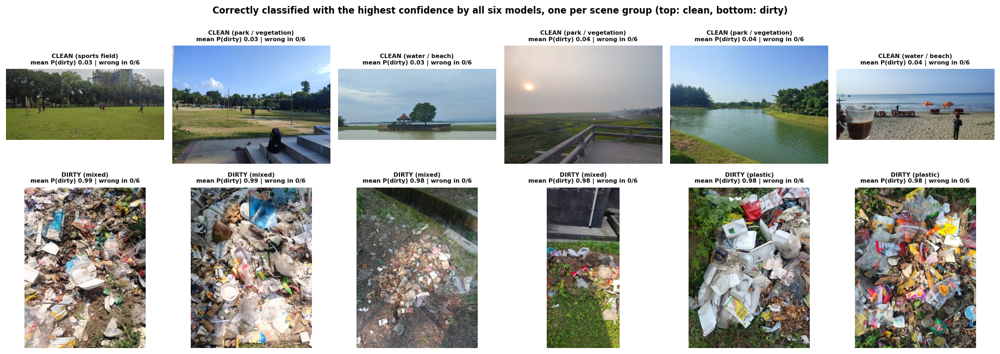

saved -> outputs\figures\fig13_incorrect.png


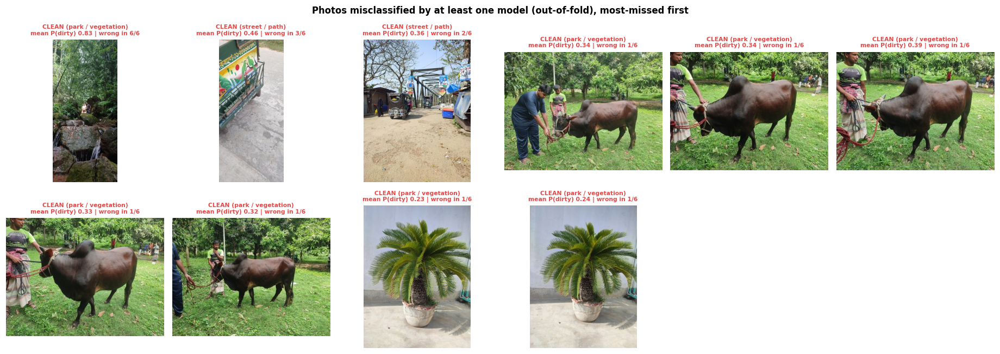

In [23]:
def gallery(files, title, name, ncol=6):
    n = len(files); nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 2.8, nrow * 3.0))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, f in zip(np.atleast_1d(axes).ravel(), files):
        r = meta.set_index("file").loc[f]; ax.imshow(CACHE[f])
        ps = [OOF.loc[f, m] for m in MODELS]
        wrongs = sum((p >= 0.5) != r.label for p in ps)
        ax.set_title(f"{r.cls.upper()} ({r.scene if r.cls == 'clean' else r.composition})\n"
                     f"mean P(dirty) {np.mean(ps):.2f} | wrong in {wrongs}/6", fontsize=7, color="#e34948" if wrongs else INK)
    plt.suptitle(title, fontweight="bold"); plt.tight_layout(); savefig(fig, name); plt.show()

rng = np.random.default_rng(1)
good = oo[oo.n_wrong == 0]
grp = meta.set_index("file").group
def top_per_group(score, n=6):
    # most confident photo of each near-duplicate group, so the gallery shows different scenes
    s = score.sort_values(ascending=False)
    return s.groupby(grp.loc[s.index].values, sort=False).head(1).index[:n].tolist()
conf_c = top_per_group(1 - good[good.label == 0][MODELS].mean(1))
conf_d = top_per_group(good[good.label == 1][MODELS].mean(1))
gallery(conf_c + conf_d, "Correctly classified with the highest confidence by all six models, one per scene group (top: clean, bottom: dirty)", "fig12_correct.png")
if len(hard): gallery(hard.index[:18].tolist(), "Photos misclassified by at least one model (out-of-fold), most-missed first", "fig13_incorrect.png")

saved -> outputs\figures\fig14_hard_cases.png


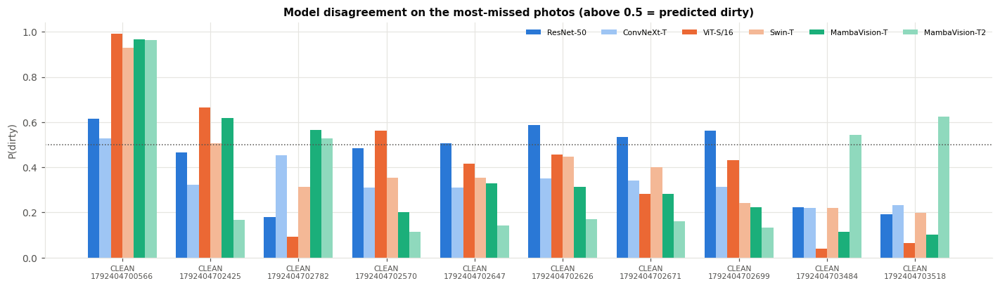

In [24]:
# per-model P(dirty) on the hardest photos
H = hard.index[:12]
fig, ax = plt.subplots(figsize=(13, 3.8))
x = np.arange(len(H))
for i, m in enumerate(MODELS):
    ax.bar(x + (i - 2.5) * 0.13, OOF.loc[H, m], 0.13, color=COL[m], label=m)
ax.axhline(0.5, color=INK2, ls=":", lw=1)
ax.set_xticks(x, [f"{meta.set_index('file').loc[f, 'cls'].upper()}\n{Path(f).stem}" for f in H], fontsize=7)
ax.set_ylabel("P(dirty)"); ax.set_title("Model disagreement on the most-missed photos (above 0.5 = predicted dirty)"); ax.legend(ncol=6, fontsize=7)
plt.tight_layout(); savefig(fig, "fig14_hard_cases.png"); plt.show()

---
# 10. Factors affecting classification and where the models look

**(a) Factors.** Out-of-fold accuracy and mean confidence grouped by scene type (clean), garbage type / background /
session (dirty), orientation, brightness and amount of sky.

**(b) Occlusion sensitivity.** A grey 32 × 32 patch is slid over the image; the drop in the predicted-class probability
shows which regions the decision depends on. This works the same way for CNN, Transformer and Mamba models.

,factor,value,class,n,ResNet-50,ConvNeXt-T,ViT-S/16,Swin-T,MambaVision-T,MambaVision-T2,mean acc,mean confidence
0,scene,building / campus,clean,23,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.938
1,scene,park / vegetation,clean,29,0.828,0.966,0.931,0.966,0.966,0.897,0.925,0.819
2,scene,sports field,clean,37,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.942
3,scene,street / path,clean,21,1.000,1.000,0.952,0.952,0.905,0.952,0.960,0.892
4,scene,water / beach,clean,30,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.939
5,composition,food,dirty,5,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.943
6,composition,garden,dirty,2,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.951
7,composition,household,dirty,2,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.932
8,composition,mixed,dirty,58,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.967
9,composition,paper,dirty,20,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.966


saved -> outputs\figures\fig15_factors.png


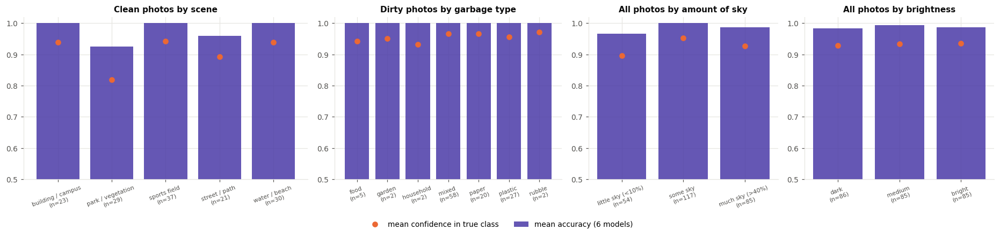

In [25]:
F_ = meta.set_index("file").copy()
for m in MODELS:
    F_[m] = ((OOF[m] >= 0.5).astype(int) == F_.label).astype(float)
F_["mean acc"] = F_[MODELS].mean(1)
F_["confidence"] = np.where(F_.label == 1, OOF[MODELS].mean(1), 1 - OOF[MODELS].mean(1))
F_["brightness level"] = pd.qcut(F_.brightness, 3, labels=["dark", "medium", "bright"])
F_["sky"] = pd.cut(F_.sky_fraction, [-1, 0.1, 0.4, 2], labels=["little sky (<10%)", "some sky", "much sky (>40%)"])
rows = []
for col, sub in [("scene", F_[F_.cls == "clean"]), ("composition", F_[F_.cls == "dirty"]), ("background", F_[F_.cls == "dirty"]),
                 ("source", F_), ("orientation", F_), ("brightness level", F_), ("sky", F_)]:
    for v, g in sub.groupby(col, observed=True):
        rows.append({"factor": col, "value": str(v), "class": "both" if sub is F_ else sub.cls.iloc[0], "n": len(g),
                     **{m: g[m].mean() for m in MODELS}, "mean acc": g["mean acc"].mean(), "mean confidence": g.confidence.mean()})
FAC = pd.DataFrame(rows); display(FAC.round(3)); FAC.round(4).to_csv(RES / "factors.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), gridspec_kw={"width_ratios": [1.5, 1.2, 1, 1]})
for ax, (fac, t) in zip(axes, [("scene", "Clean photos by scene"), ("composition", "Dirty photos by garbage type"),
                                ("sky", "All photos by amount of sky"), ("brightness level", "All photos by brightness")]):
    g = FAC[FAC.factor == fac]
    ax.bar(range(len(g)), g["mean acc"], color=PALETTE[6], alpha=0.85, label="mean accuracy (6 models)")
    ax.plot(range(len(g)), g["mean confidence"], "o", color=PALETTE[1], label="mean confidence in true class")
    ax.set_xticks(range(len(g)), [f"{v}\n(n={n})" for v, n in zip(g.value, g.n)], fontsize=7, rotation=20); ax.set_ylim(0.5, 1.02); ax.set_title(t)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(); savefig(fig, "fig15_factors.png"); plt.show()

saved -> outputs\figures\fig16_occlusion_maps.png


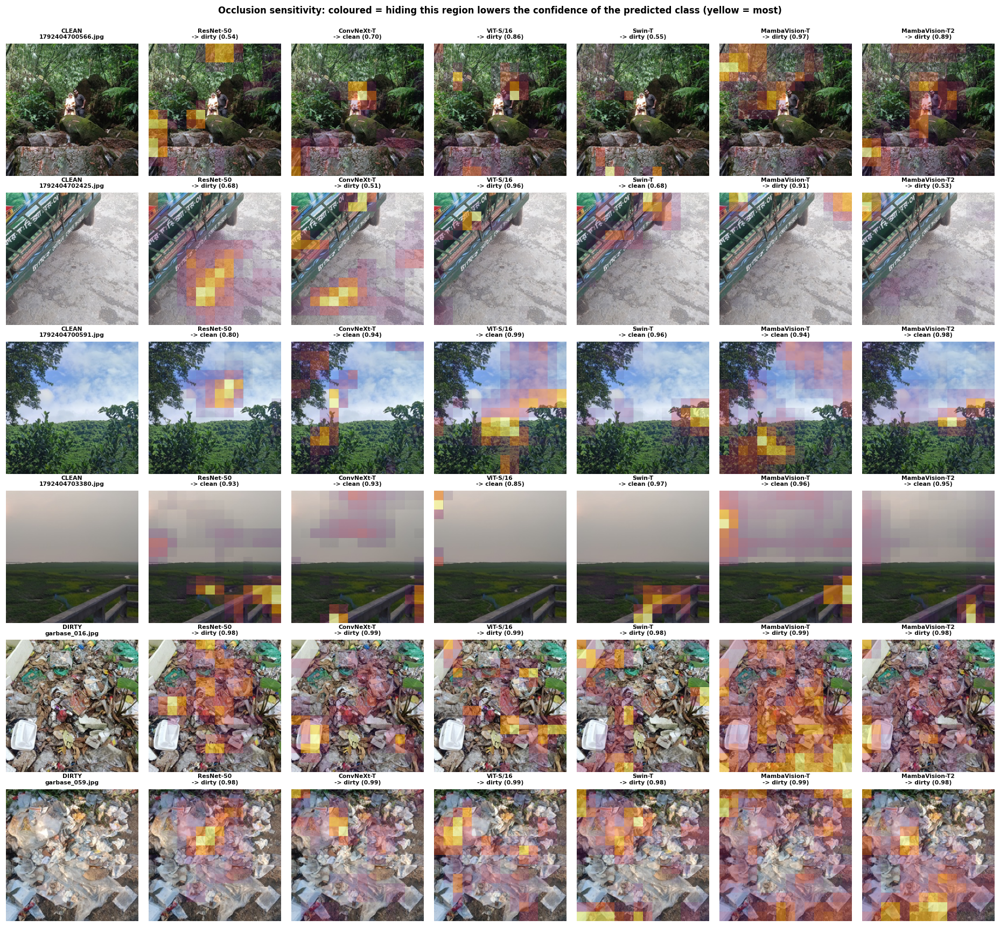

In [26]:
_tc = [f for f in TEST.file if meta.set_index("file").loc[f, "cls"] == "clean" and f not in hard.index[:2]]
_td = [f for f in TEST.file if meta.set_index("file").loc[f, "cls"] == "dirty"]
sal_files = hard.index[:2].tolist() + [_tc[0], _tc[len(_tc) // 2]] + [_td[0], _td[len(_td) // 2]]
nets = {m: T.load_trained(f"split_{tag(m)}_s0", m) for m in MODELS}
fig, axes = plt.subplots(len(sal_files), 7, figsize=(17, 2.6 * len(sal_files)))
for r, f in enumerate(sal_files):
    im = CACHE[f]; crop = E.display_crop(im)
    axes[r, 0].imshow(crop); axes[r, 0].set_title(f"{meta.set_index('file').loc[f, 'cls'].upper()}\n{Path(f).name[:20]}", fontsize=7)
    for c, m in enumerate(MODELS, 1):
        heat, pc, conf = E.occlusion_map(nets[m], im)
        hn = np.clip(heat, 0, None) / max(1e-3, heat.max())
        axes[r, c].imshow(crop); axes[r, c].imshow(hn, cmap="inferno", alpha=0.75 * hn, vmin=0, vmax=1)
        axes[r, c].set_title(f"{m}\n-> {D.CLASSES[pc]} ({conf:.2f})", fontsize=7)
for a in axes.ravel(): a.axis("off")
plt.suptitle("Occlusion sensitivity: coloured = hiding this region lowers the confidence of the predicted class (yellow = most)", fontweight="bold", y=1.0)
plt.tight_layout(); savefig(fig, "fig16_occlusion_maps.png"); plt.show()
del nets; torch.cuda.empty_cache()

---
# 11. Summary

In [27]:
S = pd.DataFrame({m: {"family": M.FAMILY[m], "test acc (3 seeds)": agg.loc[m, ("accuracy", "mean")], "test F1": agg.loc[m, ("F1", "mean")],
                      "CV acc (256)": CVM.loc[m, "accuracy"], "CV F1": CVM.loc[m, "F1"], "CV AUC": CVM.loc[m, "AUC"],
                      "corruption acc": cor.loc[m, "mean of 6"], "bottom-half: clean called dirty": vw.loc[m, ("clean called dirty", "view: bottom")],
                      "params (M)": COMP.loc[m, "params (M)"], "GMACs": COMP.loc[m, "GMACs"], "latency (ms)": COMP.loc[m, "latency_ms"],
                      "FPS bs32": COMP.loc[m, "FPS_bs32"], "train time (s)": COMP.loc[m, "train time 25 ep (s)"]} for m in MODELS}).T
display(S); S.to_csv(RES / "summary.csv")
print("figures:", len(list(FIG.glob("*.png"))), "| result files:", len(list(RES.glob("*"))))

,family,test acc (3 seeds),test F1,CV acc (256),CV F1,CV AUC,corruption acc,bottom-half: clean called dirty,params (M),GMACs,latency (ms),FPS bs32,train time (s)
ResNet-50,CNN,0.958333,0.955903,0.9805,0.9789,0.9999,0.97092,0.092857,23.51,4.09,7.41,2823.25,22.61
ConvNeXt-T,CNN,0.958333,0.956341,0.9961,0.9957,1.0,0.990668,0.021429,27.82,4.45,5.24,2882.45,22.84
ViT-S/16,Transformer,0.966667,0.964912,0.9883,0.9872,0.9938,0.966797,0.092857,21.67,4.6,5.12,4684.27,21.88
Swin-T,Transformer,0.958333,0.956341,0.9922,0.9915,0.9998,0.982856,0.164286,27.52,4.49,9.04,2107.84,25.9
MambaVision-T,Mamba,0.95,0.947806,0.9883,0.9872,0.9994,0.962023,0.1,31.15,4.6,30.66,378.23,51.25
MambaVision-T2,Mamba,0.958333,0.955903,0.9844,0.9831,0.9985,0.95638,0.107143,34.46,5.29,41.66,272.2,65.92


figures: 16 | result files: 16


**Dataset (§1–2).** 256 phone photos (140 clean, 116 dirty) in 40 + 51 near-duplicate groups; grouped split 176 / 40 / 40 with
no group shared between sets. The classes were also photographed differently: 75 % of the dirty photos are portrait close-ups
of the ground, 78 % of the clean photos are landscape views with sky. Orientation and resolution alone already give 76 %
accuracy (AUC 0.89); a colour histogram gives 64 %. The deep models must therefore be judged with this in mind (§8).

**Classification performance (§4–5).** All six backbones solve the task almost perfectly, and the differences between them are
smaller than one or two photos:

| | ResNet-50 | ConvNeXt-T | ViT-S/16 | Swin-T | MambaVision-T | MambaVision-T2 |
|---|---|---|---|---|---|---|
| test accuracy, 3 seeds (40 photos) | 95.8 | 95.8 | **96.7** | 95.8 | 95.0 | 95.8 |
| 5-fold CV accuracy (256 photos) | 98.0 | **99.6** | 98.8 | 99.2 | 98.8 | 98.4 |
| 5-fold CV F1 (dirty) | 97.9 | **99.6** | 98.7 | 99.2 | 98.7 | 98.3 |

Recall for *dirty* is 1.00 for every model in every run: no garbage photo was ever missed. All errors are clean photos called
dirty, so precision (0.96–0.99) is the metric that separates the models. Averaged per family, CV accuracy is CNN 98.8 %,
Transformer 99.0 %, Mamba 98.6 %. That is no meaningful difference on a dataset of this size.

**Computational requirements and speed (§6).** The models have similar size (22–34 M parameters, 4.1–5.3 GMACs). In practice
ViT-S/16 and ConvNeXt-T have the lowest latency (≈5 ms per image) and ViT-S/16 the highest throughput (≈4700 images/s at
batch 32); ResNet-50 is close behind and Swin-T is about half as fast. MambaVision has 3–8× higher latency, up to 17× lower throughput and needs 3–6× more training memory **in this setup**, because its selective scan
runs as a pure-PyTorch loop instead of the fused CUDA kernel (which cannot be built on Windows). Its FLOP count shows it is
not intrinsically heavier.

**Training configurations (§7).** A linear probe on the frozen ImageNet features already reaches 92.5–97.5 % test accuracy,
the same as full fine-tuning for five of the six models. Even 18 training images give 92–98 %. The concepts "garbage" and
"open clean scene" are already present in ImageNet features, so the backbone family matters little for accuracy here.

**Robustness and shortcuts (§8).** ConvNeXt-T is the most robust (99.1 % mean accuracy over six corruptions). The two
MambaVision models are the most sensitive to strong noise (70 % / 78 %) and blur (MambaVision-T2: 79 %). ViT-S/16 is the most
sensitive to darkening and overexposure. When only the bottom half of the photo is shown (no sky, ground only), garbage
is still found (≤ 3.5 % of dirty photos missed), but 2–16 % of clean photos are now called dirty (ConvNeXt-T 2 %, Swin-T 16 %). The
models have learned garbage textures, but for the clean class they partly rely on the wide-scene layout.

**Correct and incorrect classifications, factors (§9–10).** 246 of 256 photos are classified correctly by all six models. The
ten that are not are all clean scenes that look like the dirty set:
* a dark, cluttered forest / rock scene in portrait format (wrong for all six models);
* close-ups of a dusty road surface;
* grass with fallen leaves and cattle.

Park / vegetation is the hardest clean scene (92.5 % mean accuracy). Photos with little sky (< 10 %) are harder (96.6 %) than
photos with some or much sky (98.5–100 %). Brightness has little effect. The occlusion maps show that dirty decisions are
spread over the pieces of garbage, while clean decisions depend on the scene as a whole.

**Conclusion.** All three families classify clean vs. dirty places with ≥ 98 % cross-validated accuracy. **ConvNeXt-T** has the
best overall balance: highest CV accuracy, most robust, and among the fastest. **ViT-S/16** is the fastest and has the best
held-out test score. **MambaVision** matches them in accuracy but is the slowest here and the least robust to noise and blur.
The main limitation is the dataset: the two classes differ in viewpoint and camera, so a larger set with clean and dirty
photos taken at the same places and from the same distance is needed before deployment.